# 03_Overnight rebalancing optimization and simulation
Turns the station-level forecasts into an overnight rebalancing plan for each test weekday, solved as a linear program with an external depot. Each plan is replayed against the actual trips of the next morning to count failed pickups and returns. Safety buffers on the forecast bike and dock needs are tuned on the validation week, and the forecast-driven plans are compared with no rebalancing, a rule-based plan and a plan built on a perfect forecast.

## 1. Load data

| Name | Source | Role |
|---|---|---|
| `stations` | `data/processed/study_stations.parquet` | Station capacity and location |
| `forecasts` | `data/processed/forecasts.parquet` | Hourly LightGBM forecasts and actuals for the validation and test periods |
| `history` | `data/processed/panel.parquet` | Pre-test station history, used by the rule-based plan |
| `events` | `data/processed/trips_*.parquet` | Actual trips in the validation and test periods, replayed in the simulation |

### Assumptions

| Parameter | Value | Meaning |
|---|---|---|
| Window | 6–10 AM, weekdays | Planning and simulation window; rebalancing finishes before 6 AM |
| Starting inventory | 50% of capacity | Inventory before rebalancing; actual overnight inventory is not observed |
| `penalty` | 10 | Cost of one expected failed pickup or return |
| `cost_per_km` | 1 | Cost of moving one bike one km between stations |
| `depot_cost` | 3 | Cost of moving one bike to or from the depot outside the area |
| `max_pair_km` | 2 | Longest station-to-station move considered |
| `k_bikes`, `k_docks` | Tuned on validation | Safety buffers for bikes and for free docks, in multiples of the forecast's Poisson standard deviation |

In [51]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.sparse import coo_matrix

duckdb.sql("SET enable_progress_bar = false")
processed_dir = '../data/processed'

valid_start = '2025-09-08'
test_start, test_end = '2025-09-15', '2025-10-01'
window_start_hr, window_end_hr = 6, 10

start_fill  = 0.5
penalty     = 10.0
cost_per_km = 1.0
depot_cost  = 3.0
max_pair_km = 2.0

### Load stations and forecasts
Stations are sorted by `station_id`; every array below follows this order. Forecasts are split into the validation week and the test period.

In [52]:
stations = duckdb.sql(f"""
SELECT station_id, name, lat, lng, capacity, capacity_source
FROM '{processed_dir}/study_stations.parquet'
ORDER BY station_id
""").df()

forecasts_all = duckdb.sql(f"""
SELECT *
FROM '{processed_dir}/forecasts.parquet'
WHERE day_type = 'weekday'
  AND hr >= {window_start_hr}
  AND hr <  {window_end_hr}
""").df()

forecasts_valid = forecasts_all[forecasts_all['split'] == 'valid']
forecasts       = forecasts_all[forecasts_all['split'] == 'test']

station_ids = stations['station_id'].to_numpy()
station_idx = {s: i for i, s in enumerate(station_ids)}
cap = stations['capacity'].to_numpy()
n = len(stations)
valid_days = sorted(forecasts_valid['date'].unique())
test_days  = sorted(forecasts['date'].unique())

print(f'{n} stations')
print(f'{len(valid_days)} validation weekdays: {valid_days[0].date()} to {valid_days[-1].date()}')
print(f'{len(test_days)} test weekdays: {test_days[0].date()} to {test_days[-1].date()}')

229 stations
5 validation weekdays: 2025-09-08 to 2025-09-12
12 test weekdays: 2025-09-15 to 2025-09-30


### Load trip events for the simulation
One row per departure (−1) or arrival (+1) at a study station inside the window, in time order. The cleaning rules match `00_data_ingest`.

In [53]:
events = duckdb.sql(f"""
WITH clean AS (
    SELECT *
    FROM '{processed_dir}/trips_*.parquet'
    WHERE started_at >= '{valid_start}'
      AND started_at <  '{test_end}'
      AND date_diff('second', started_at, ended_at) BETWEEN 60 AND 3 * 3600
),
stations AS (
    SELECT station_id FROM '{processed_dir}/study_stations.parquet'
)
SELECT start_station_id AS station_id, started_at AS ts, -1 AS delta
FROM clean
WHERE start_station_id IN (SELECT station_id FROM stations)
  AND hour(started_at) >= {window_start_hr} AND hour(started_at) < {window_end_hr}
  AND dayofweek(started_at) BETWEEN 1 AND 5
UNION ALL
SELECT end_station_id, ended_at, 1
FROM clean
WHERE end_station_id IN (SELECT station_id FROM stations)
  AND hour(ended_at) >= {window_start_hr} AND hour(ended_at) < {window_end_hr}
  AND dayofweek(ended_at) BETWEEN 1 AND 5
ORDER BY ts
""").df()

events['date'] = events['ts'].dt.normalize()
events['idx'] = events['station_id'].map(station_idx)

events.groupby('date').agg(
    departures=('delta', lambda d: (d < 0).sum()),
    arrivals=('delta', lambda d: (d > 0).sum()),
)

,departures,arrivals
date,,
2025-09-08,11840,14145
2025-09-09,13829,16874
2025-09-10,8557,10121
2025-09-11,12869,15736
2025-09-12,10561,12478
2025-09-15,12001,14507
2025-09-16,13646,16681
2025-09-17,13640,16772
2025-09-18,12947,15872


## 2. Planning inputs

### Bike and dock needs per station
For each station and day, the cumulative net flow from 6 AM (arrivals − departures, hour by hour) shows how many bikes must be on hand to avoid running empty (`need_bikes`) and how many free docks are needed to avoid filling up (`need_docks`). A station's starting inventory should therefore lie between `need_bikes` and `capacity − need_docks`.

Forecasts are expected values, so planning exactly to them leaves no room for random variation. `sigma` is the Poisson standard deviation of the station's total expected trips in the window, √(departures + arrivals). As in safety-stock planning, `k_bikes × sigma` is added to `need_bikes` and `k_docks × sigma` to `need_docks`. Separate buffers allow more protection on the side that fails more often.

In [54]:
def need_bounds(fc, dep_col, arr_col):
    fc = fc.sort_values(['station_id', 'date', 'hr']).copy()
    fc['cum_net'] = (fc[arr_col] - fc[dep_col]).groupby([fc['station_id'], fc['date']]).cumsum()
    fc['gross'] = fc[arr_col] + fc[dep_col]
    bounds = fc.groupby(['station_id', 'date']).agg(
        cum_min=('cum_net', 'min'),
        cum_max=('cum_net', 'max'),
        gross=('gross', 'sum'),
    ).reset_index()
    bounds['need_bikes'] = (-bounds['cum_min']).clip(lower=0)
    bounds['need_docks'] = bounds['cum_max'].clip(lower=0)
    bounds['sigma'] = np.sqrt(bounds['gross'])
    return bounds[['station_id', 'date', 'need_bikes', 'need_docks', 'sigma']]

bounds_valid  = need_bounds(forecasts_valid, 'departures_lgbm', 'arrivals_lgbm')
bounds_lgbm   = need_bounds(forecasts, 'departures_lgbm', 'arrivals_lgbm')
bounds_actual = need_bounds(forecasts, 'departures', 'arrivals')

def bounds_for_day(bounds, day, k_bikes=0.0, k_docks=0.0):
    b = bounds[bounds['date'] == day].set_index('station_id').reindex(station_ids).fillna(0)
    sigma = b['sigma'].to_numpy()
    lower = b['need_bikes'].to_numpy() + k_bikes * sigma
    upper = cap - b['need_docks'].to_numpy() - k_docks * sigma
    return lower, upper

### Conflicting stations
A station whose `need_bikes` exceeds `capacity − need_docks` cannot avoid every failure with a single overnight refill. Counted per day, using the LightGBM forecast.

In [55]:
conflicts = []
for day in test_days:
    lower, upper = bounds_for_day(bounds_lgbm, day)
    conflicts.append({'date': day.date(), 'conflicting_stations': int((lower > upper).sum())})

pd.DataFrame(conflicts)

,date,conflicting_stations
0,2025-09-15,10
1,2025-09-16,11
2,2025-09-17,10
3,2025-09-18,11
4,2025-09-19,8
5,2025-09-22,8
6,2025-09-23,11
7,2025-09-24,14
8,2025-09-25,10
9,2025-09-26,7


## 3. Optimization model

### Linear program
For each test day, the model chooses each station's starting inventory and the moves that produce it.

| Variable | Meaning |
|---|---|
| `s_i` | Starting inventory at station *i* after rebalancing, between 0 and capacity |
| `x_ij` | Bikes moved from station *i* to station *j* (pairs within `max_pair_km`) |
| `in_i`, `out_i` | Bikes brought from or taken to the depot |
| `short_i`, `over_i` | Expected shortfall of bikes and of free docks |

Minimize `penalty × Σ(short + over) + cost_per_km × Σ dist_ij·x_ij + depot_cost × Σ(in + out)`, subject to

- inventory balance: `s_i = s0_i + Σ_j x_ji − Σ_j x_ij + in_i − out_i`
- `short_i ≥ need_bikes_i − s_i` and `over_i ≥ s_i − (capacity_i − need_docks_i)`

The problem is solved with SciPy's HiGHS LP solver; the resulting inventories are rounded to whole bikes.

In [56]:
# Haversine distance between every pair of stations, in km
lat = np.radians(stations['lat'].to_numpy())
lng = np.radians(stations['lng'].to_numpy())
a = (np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
     + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lng[:, None] - lng[None, :]) / 2) ** 2)
dist = 2 * 6371 * np.arcsin(np.sqrt(a))

pair_i, pair_j = np.where((dist <= max_pair_km) & ~np.eye(n, dtype=bool))
m = len(pair_i)
print(f'{m:,} station pairs within {max_pair_km} km')

28,678 station pairs within 2.0 km


In [57]:
def solve_rebalancing(s0, lower, upper):
    # variable order: s (n) | x (m) | in (n) | out (n) | short (n) | over (n)
    o_s, o_x, o_in, o_out, o_short, o_over = 0, n, n + m, 2 * n + m, 3 * n + m, 4 * n + m
    n_vars = 5 * n + m
    rows_n, idx_n = np.arange(n), np.arange(n)

    c = np.zeros(n_vars)
    c[o_x:o_x + m] = cost_per_km * dist[pair_i, pair_j]
    c[o_in:o_out + n] = depot_cost
    c[o_short:o_over + n] = penalty

    # inventory balance: s_i - inflow_i + outflow_i - in_i + out_i = s0_i
    eq_r = np.concatenate([rows_n, pair_j, pair_i, rows_n, rows_n])
    eq_c = np.concatenate([o_s + idx_n, o_x + np.arange(m), o_x + np.arange(m), o_in + idx_n, o_out + idx_n])
    eq_v = np.concatenate([np.ones(n), -np.ones(m), np.ones(m), -np.ones(n), np.ones(n)])
    A_eq = coo_matrix((eq_v, (eq_r, eq_c)), shape=(n, n_vars)).tocsr()

    # -s_i - short_i <= -lower_i   and   s_i - over_i <= upper_i
    ub_r = np.concatenate([rows_n, rows_n, n + rows_n, n + rows_n])
    ub_c = np.concatenate([o_s + idx_n, o_short + idx_n, o_s + idx_n, o_over + idx_n])
    ub_v = np.concatenate([-np.ones(n), -np.ones(n), np.ones(n), -np.ones(n)])
    A_ub = coo_matrix((ub_v, (ub_r, ub_c)), shape=(2 * n, n_vars)).tocsr()
    b_ub = np.concatenate([-lower, upper])

    var_bounds = [(0, cap_i) for cap_i in cap] + [(0, None)] * (n_vars - n)
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=s0, bounds=var_bounds, method='highs')
    assert res.status == 0, res.message

    v = res.x
    x = v[o_x:o_x + m]
    return {
        'start':        np.clip(np.round(v[o_s:o_s + n]), 0, cap).astype(int),
        'station_moves': x.sum(),
        'bike_km':      (x * dist[pair_i, pair_j]).sum(),
        'depot_in':     v[o_in:o_in + n].sum(),
        'depot_out':    v[o_out:o_out + n].sum(),
    }

### Rule-based plan
A simple operator rule without forecasts: using pre-test weekday history, stations that lose more than 5 bikes between 7 and 10 AM are filled to 90% of capacity, stations that gain more than 5 are emptied to 10%, and the rest are set to 50%. The LP then finds the cheapest moves that reach these targets.

In [58]:
am_net_hist = duckdb.sql(f"""
SELECT station_id,
       SUM(arrivals - departures) / COUNT(DISTINCT date) AS am_net
FROM '{processed_dir}/panel.parquet'
WHERE date < '{test_start}'
  AND day_type = 'weekday'
  AND hr BETWEEN 7 AND 9
GROUP BY station_id
""").df().set_index('station_id').reindex(station_ids)['am_net'].fillna(0).to_numpy()

rule_fill = np.where(am_net_hist < -5, 0.9, np.where(am_net_hist > 5, 0.1, 0.5))
rule_target = np.round(rule_fill * cap)

s0 = np.round(start_fill * cap)
rule_plan = solve_rebalancing(s0, rule_target, rule_target)
print({k: round(v, 1) for k, v in rule_plan.items() if k != 'start'})

{'station_moves': np.float64(1721.0), 'bike_km': np.float64(1296.2), 'depot_in': np.float64(0.0), 'depot_out': np.float64(1166.0)}


## 4. Simulation

### Replay actual trips
Starting from a plan's inventories, events are processed in time order. A departure at an empty station is a failed pickup; an arrival at a full station is a failed return. Failed trips are not re-routed, and their downstream arrivals still occur, so the counts are an approximation.

In [59]:
def simulate(start, day_events):
    inv = start.copy()
    failed_pickups = failed_returns = 0
    for i, delta in zip(day_events['idx'].to_numpy(), day_events['delta'].to_numpy()):
        if delta < 0:
            if inv[i] > 0:
                inv[i] -= 1
            else:
                failed_pickups += 1
        else:
            if inv[i] < cap[i]:
                inv[i] += 1
            else:
                failed_returns += 1
    return failed_pickups, failed_returns

### Total cost
Scores a simulated day with the same weights as the LP, so strategies that move more bikes are charged for it.

In [60]:
def total_cost(failures, plan):
    return (penalty * failures
            + cost_per_km * plan['bike_km']
            + depot_cost * (plan['depot_in'] + plan['depot_out']))

## 5. Safety buffer

### Tune `k_bikes` and `k_docks` on the validation week
Solves and simulates every validation weekday for each pair of buffers and records the average total cost. Two settings are kept: the best symmetric buffer (`k_bikes = k_docks`) and the best pair overall. The test period is not used. This runs 150 LP solves and takes a few minutes.

In [61]:
k_bikes_grid = [0.0, 0.5, 1.0, 1.5, 2.0]
k_docks_grid = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]

tuning = []
for k_bikes in k_bikes_grid:
    for k_docks in k_docks_grid:
        for day in valid_days:
            plan = solve_rebalancing(s0, *bounds_for_day(bounds_valid, day, k_bikes, k_docks))
            fp, fr = simulate(plan['start'], events[events['date'] == day])
            tuning.append({'k_bikes': k_bikes, 'k_docks': k_docks,
                           'failed_pickups': fp, 'failed_returns': fr,
                           'cost': total_cost(fp + fr, plan),
                           'station_moves': plan['station_moves'],
                           'depot_moves': plan['depot_in'] + plan['depot_out']})

tuning = pd.DataFrame(tuning).groupby(['k_bikes', 'k_docks']).mean().reset_index()

symmetric = tuning[tuning['k_bikes'] == tuning['k_docks']]
k_sym = symmetric.loc[symmetric['cost'].idxmin(), 'k_bikes']
k_bikes_best, k_docks_best = tuning.loc[tuning['cost'].idxmin(), ['k_bikes', 'k_docks']]
print(f'Best symmetric buffer: k = {k_sym}')
print(f'Best pair: k_bikes = {k_bikes_best}, k_docks = {k_docks_best}')

Best symmetric buffer: k = 1.0
Best pair: k_bikes = 0.5, k_docks = 2.0


### Validation cost by buffer pair
Average total cost per validation weekday; rows are `k_bikes`, columns `k_docks`.

In [62]:
tuning.pivot(index='k_bikes', columns='k_docks', values='cost').round(0)

k_docks,0.0,0.5,1.0,1.5,2.0,3.0
k_bikes,,,,,,
0.0,18820.0,16702.0,14462.0,13225.0,13103.0,15623.0
0.5,18187.0,16199.0,14200.0,12859.0,12407.0,13500.0
1.0,17505.0,15912.0,14426.0,13430.0,12747.0,12847.0
1.5,17271.0,16020.0,15232.0,14552.0,14192.0,13563.0
2.0,16908.0,16397.0,16305.0,16416.0,16323.0,16074.0


### Selected settings on validation

In [63]:
selected = pd.concat([
    tuning[(tuning['k_bikes'] == 0) & (tuning['k_docks'] == 0)].assign(setting='No buffer'),
    tuning[(tuning['k_bikes'] == k_sym) & (tuning['k_docks'] == k_sym)].assign(setting='Best symmetric'),
    tuning[(tuning['k_bikes'] == k_bikes_best) & (tuning['k_docks'] == k_docks_best)].assign(setting='Best pair'),
])
selected.set_index('setting').round(1)

,k_bikes,k_docks,failed_pickups,failed_returns,cost,station_moves,depot_moves
setting,,,,,,,
No buffer,0.0,0.0,508.6,1353.8,18819.8,623.5,0.0
Best symmetric,1.0,1.0,380.6,1011.0,14425.9,1077.4,0.0
Best pair,0.5,2.0,392.4,683.6,12407.4,1433.3,218.9


**Key findings: safety buffer**
- Without a buffer the plan moves only 624 bikes a night, because it plans exactly to expected demand, and validation cost is 18,820.
- The best symmetric buffer (`k = 1`) cuts validation cost to 14,426 but leaves most failed returns in place (1,011 per weekday).
- The best pair is `k_bikes = 0.5`, `k_docks = 2.0`, with a validation cost of 12,407 (−14% vs. the best symmetric buffer). A larger dock buffer cuts failed returns by 32% (1,011 to 684) and is the first setting that sends bikes to the depot (219 per night).
- The optimum lies inside the grid on both axes, and cost rises again at `k_docks = 3` and `k_bikes = 2`: over-buffering pushes needs past station capacity and adds moves without avoiding more failures.

## 6. Test results

### Run all strategies
Six strategies per test weekday. *Perfect forecast* uses the actual hourly counts with no buffer and shows what better forecasting could deliver.

In [64]:
no_move = {'start': s0.astype(int), 'station_moves': 0.0, 'bike_km': 0.0, 'depot_in': 0.0, 'depot_out': 0.0}

records, lgbm_plans = [], {}
for day in test_days:
    day_events = events[events['date'] == day]
    plans = {
        'No rebalancing':               no_move,
        'Rule-based':                   rule_plan,
        'Optimized (LightGBM)':         solve_rebalancing(s0, *bounds_for_day(bounds_lgbm, day)),
        'Optimized (LightGBM + buffer)': solve_rebalancing(s0, *bounds_for_day(bounds_lgbm, day, k_sym, k_sym)),
        'Optimized (LightGBM + asymmetric buffer)':
            solve_rebalancing(s0, *bounds_for_day(bounds_lgbm, day, k_bikes_best, k_docks_best)),
        'Optimized (perfect forecast)': solve_rebalancing(s0, *bounds_for_day(bounds_actual, day)),
    }
    lgbm_plans[day] = plans['Optimized (LightGBM + asymmetric buffer)']
    for strategy, plan in plans.items():
        fp, fr = simulate(plan['start'], day_events)
        records.append({
            'date': day.date(), 'strategy': strategy, 'events': len(day_events),
            'failed_pickups': fp, 'failed_returns': fr,
            'total_cost': total_cost(fp + fr, plan),
            **{key: v for key, v in plan.items() if key != 'start'},
        })

results = pd.DataFrame(records)
results['failures'] = results['failed_pickups'] + results['failed_returns']

## 5. Results

### Average per test weekday
`failure_pct` is failures as a share of all departures and arrivals in the window. Move columns are bikes per night. `total_cost` uses the LP weights.

In [65]:
summary = (
    results
    .groupby('strategy', sort=False)[['failed_pickups', 'failed_returns', 'failures', 'events',
                                      'station_moves', 'bike_km', 'depot_in', 'depot_out', 'total_cost']]
    .mean()
)
summary['failure_pct'] = 100 * summary['failures'] / summary['events']
summary['failures_vs_none_pct'] = 100 * (summary['failures'] / summary.loc['No rebalancing', 'failures'] - 1)

summary.drop(columns='events').round(1)

,failed_pickups,failed_returns,failures,station_moves,bike_km,depot_in,depot_out,total_cost,failure_pct,failures_vs_none_pct
strategy,,,,,,,,,,
No rebalancing,668.8,1882.4,2551.2,0.0,0.0,0.0,0.0,25511.7,9.6,0.0
Rule-based,332.4,674.2,1006.7,1721.0,1296.2,0.0,1166.0,14860.9,3.8,-60.5
Optimized (LightGBM),509.5,1312.2,1821.7,1008.0,404.5,0.0,0.0,18621.1,6.9,-28.6
Optimized (LightGBM + buffer),383.2,1022.9,1406.1,1318.5,707.9,0.0,0.0,14768.8,5.3,-44.9
Optimized (LightGBM + asymmetric buffer),360.8,696.3,1057.2,1518.5,1059.2,0.0,394.0,12812.9,4.0,-58.6
Optimized (perfect forecast),282.2,560.3,842.6,1561.9,715.8,0.0,0.0,9141.6,3.2,-67.0


### Failures by strategy

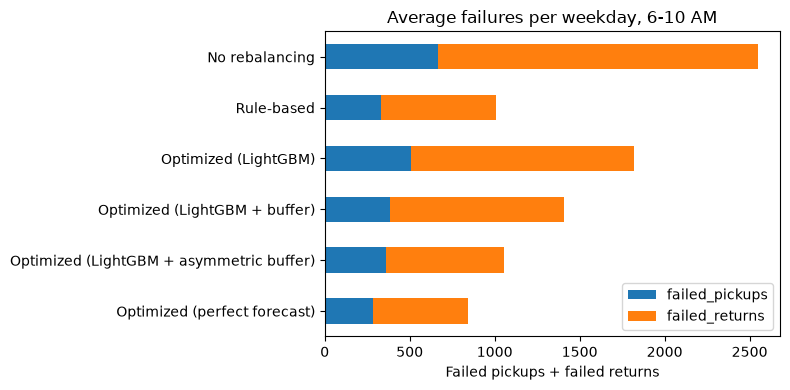

In [66]:
fig, ax = plt.subplots(figsize=(8, 4))
summary[['failed_pickups', 'failed_returns']].plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_title('Average failures per weekday, 6-10 AM')
ax.set_xlabel('Failed pickups + failed returns')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### Rebalancing plan for the first test day
Change in starting inventory from the LightGBM + asymmetric buffer plan. Blue stations receive bikes (morning outflow stations); red stations give bikes up to free docks (morning inflow stations).

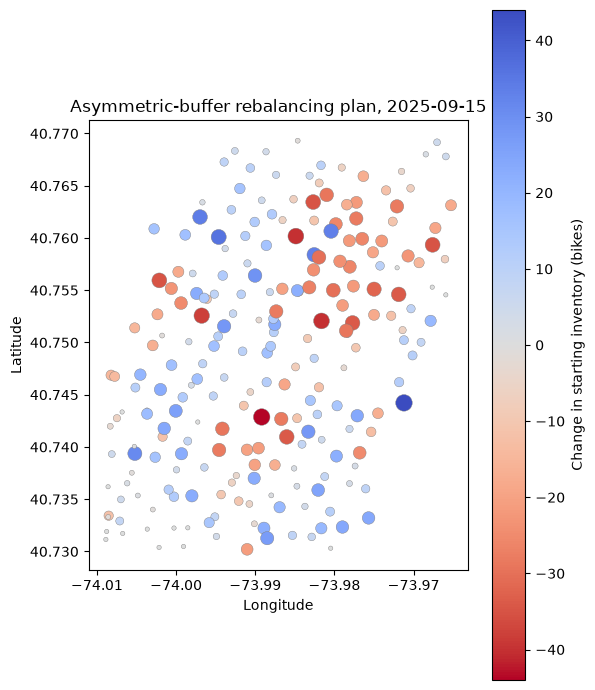

In [67]:
first_day = test_days[0]
change = lgbm_plans[first_day]['start'] - s0

fig, ax = plt.subplots(figsize=(6, 7))
sc = ax.scatter(stations['lng'], stations['lat'], c=change, cmap='coolwarm_r',
                vmin=-np.abs(change).max(), vmax=np.abs(change).max(),
                s=10 + np.abs(change) * 3, edgecolor='gray', linewidth=0.3)
fig.colorbar(sc, ax=ax, label='Change in starting inventory (bikes)')
ax.set_title(f'Asymmetric-buffer rebalancing plan, {first_day.date()}')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect(1 / np.cos(np.radians(40.75)))
plt.tight_layout()
plt.show()

**Key findings: test results**
- Without rebalancing, 9.6% of morning pickups and returns fail (2,551 per weekday), and 74% of failures are returns to full stations.
- The asymmetric-buffer plan has the lowest total cost of all practical strategies: 12,813 per weekday vs. 14,861 for the rule-based plan (−13.8%). Its validation cost (12,407) was close, so the tuned buffers carry over to the test period.
- It cuts failures by 58.6%, close to the rule-based plan's 60.5% (1,057 vs. 1,007 per weekday), while handling 34% fewer bikes (1,913 vs. 2,887 moved between stations or to the depot), 18% fewer bike-km (1,059 vs. 1,296) and 66% fewer depot trips (394 vs. 1,166).
- Each refinement adds value: the forecast-driven plan reduces failures by 28.6% with no buffer, 44.9% with a symmetric buffer and 58.6% with separate bike and dock buffers.
- A perfect forecast would lower total cost to 9,142. The asymmetric buffer closes 36% of the gap between the rule-based plan and that benchmark; better peak forecasting is the main remaining lever.
- About 10 stations per test day need more bikes and free docks than their capacity allows, so no overnight plan can avoid every failure there.

## 7. Save outputs

### Save simulation results
One row per test weekday and strategy.

In [68]:
duckdb.sql(f"""
COPY results TO '{processed_dir}/rebalancing_results.parquet' (FORMAT PARQUET)
""")